# 6-loyiha
Logistik regressiya va Random Forest taqqoslash

heart_disease.csv: sun’iy yurak xavfi ma’lumotlari. Target simulyatsiya formulasi bilan yaratilgan, klinik tashxis emas.


In [1]:
# Logistik regressiya va Random Forest taqqoslash
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    brier_score_loss, ConfusionMatrixDisplay)

def binary_metrics(y, probability, threshold=0.5):
    pred = np.asarray(probability) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=int(len(y)), threshold=float(threshold),
        accuracy=float(accuracy_score(y, pred)),
        precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)),
        specificity=float(tn / (tn + fp)) if tn + fp else None,
        f1=float(f1_score(y, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y, probability))
            if len(np.unique(y)) == 2 else None,
        brier=float(brier_score_loss(y, probability)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibrationDisplay

def main():
    path = DATA / "heart_disease.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        n = 700
        age = rng.integers(25, 86, n)
        bp = rng.normal(130, 22, n)
        bmi = rng.normal(27, 5, n)
        sex = rng.choice(["A", "B"], n)
        z = -1.6 + (age - 50) / 22 + (bp - 120) / 35
        prob = 1 / (1 + np.exp(-z))
        pd.DataFrame({"patient_id": np.arange(n), "age": age,
            "bmi": bmi, "systolic_bp": bp, "sex_group": sex,
            "target": rng.binomial(1, prob)}).to_csv(path, index=False)
    df = pd.read_csv(path)
    if df.patient_id.duplicated().any():
        raise ValueError("Bemor takrori: guruhli split zarur")
    train, hold = train_test_split(df.index, test_size=0.4,
        random_state=SEED, stratify=df.target)
    val, test = train_test_split(hold, test_size=0.5,
        random_state=SEED, stratify=df.loc[hold, "target"])
    X, y = df.drop(columns=["patient_id", "target"]), df.target
    prep = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(), StandardScaler()),
         ["age", "bmi", "systolic_bp"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["sex_group"])])
    models = {"LogisticRegression": LogisticRegression(max_iter=2000),
        "RandomForest": RandomForestClassifier(n_estimators=120,
            min_samples_leaf=8, random_state=SEED, n_jobs=1)}
    fitted, rows = {}, []
    for name, estimator in models.items():
        fitted[name] = make_pipeline(prep, estimator)
        fitted[name].fit(X.loc[train], y.loc[train])
        p = fitted[name].predict_proba(X.loc[val])[:, 1]
        rows.append({"model": name, **binary_metrics(y.loc[val], p)})
    table = pd.DataFrame(rows).sort_values("roc_auc", ascending=False)
    table.to_csv(OUT / "validation_comparison.csv", index=False)
    name = table.iloc[0]["model"]
    model = fitted[name]
    vp = model.predict_proba(X.loc[val])[:, 1]
    candidates = [binary_metrics(y.loc[val], vp, t)
                  for t in np.linspace(0.05, 0.95, 37)]
    feasible = [r for r in candidates if r["recall"] >= 0.85]
    selected = max(feasible, key=lambda r: r["specificity"])
    threshold = selected["threshold"]
    pd.DataFrame(candidates).to_csv(OUT / "thresholds_val.csv", index=False)
    p = model.predict_proba(X.loc[test])[:, 1]
    result = binary_metrics(y.loc[test], p, threshold)
    save_json("metrics.json", {"selected_model": name,
        "source": "synthetic", "test": result})
    pd.DataFrame({"patient_id": df.loc[test, "patient_id"],
        "y_true": y.loc[test], "probability": p}).to_csv(
        OUT / "predictions.csv", index=False)
    ConfusionMatrixDisplay.from_predictions(y.loc[test], p >= threshold)
    save_plot("confusion_matrix.png")
    CalibrationDisplay.from_predictions(y.loc[test], p, n_bins=6)
    save_plot("calibration.png")
    joblib.dump(model, OUT / "model.joblib")
    save_json("split.json", {"train": train.tolist(),
        "validation": val.tolist(), "test": test.tolist()})
    print(json.dumps(result, indent=2))

if __name__ == "__main__":
    main()


{
  "n": 140,
  "threshold": 0.15,
  "accuracy": 0.5214285714285715,
  "precision": 0.3711340206185567,
  "recall": 0.8571428571428571,
  "specificity": 0.37755102040816324,
  "f1": 0.5179856115107914,
  "roc_auc": 0.728377065111759,
  "brier": 0.17953509532236078,
  "tn": 37,
  "fp": 61,
  "fn": 6,
  "tp": 36
}


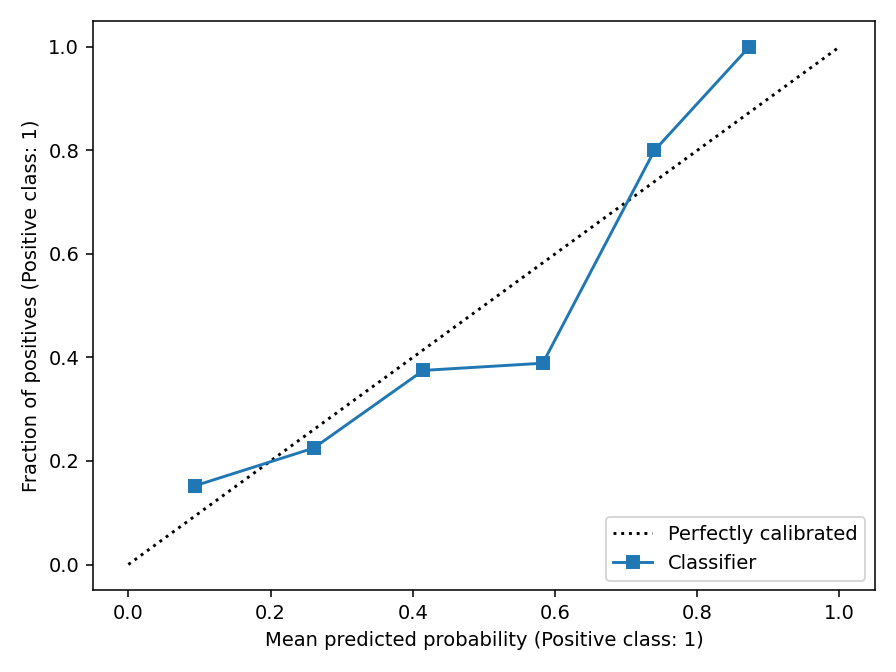

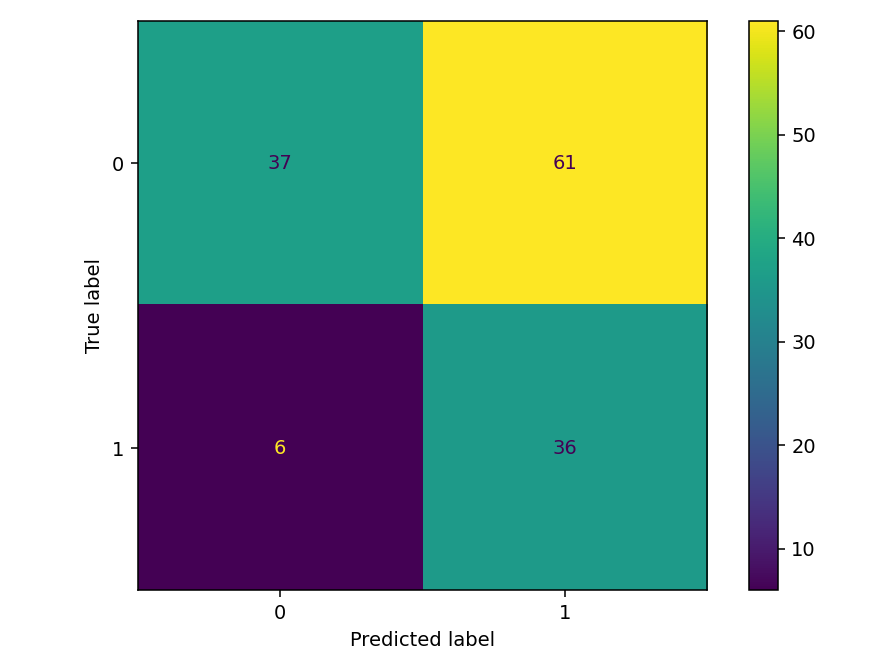

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
